# Self-lensing light curves

A deterministic self-lensing signal, plus Gaussian-process (GP) and independent-Gaussian-noise realizations with the same signal as their mean.

This notebook first constructs and visualizes those curves, then compares their Fourier amplitude, power, and PSD representations. The final section is the worked detection example: it estimates a robust noise PSD without pre-locating the pulse, uses that PSD to whiten an FFT-domain correlation, and searches over template time shifts.

In [32]:
import os

# Keep this compact example on the CPU when a GPU is shared or unavailable.
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from selflensing.models import SelfLensingSystem
from selflensing.generators import SelfLensingLightcurveGenerator
import jax
from tinygp import GaussianProcess, kernels
from math import ceil


Orbital period: 3482.59 days


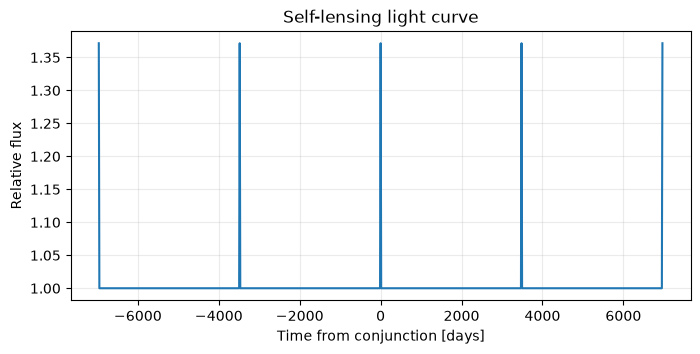

In [33]:
# A near edge-on black-hole--star binary that produces a visible self-lensing pulse.
system = SelfLensingSystem(
    Macc=10 * u.M_sun,
    Mcomp=1 * u.M_sun,
    Rcomp=1 * u.R_sun,
    a=10 * u.au,
    i=np.pi / 2 * u.rad,
    d=1 * u.kpc,
)

orbital_period_days = float(system.porb.to(u.day).value)
print(f"Orbital period: {orbital_period_days:.2f} days")

# Keep the time grid numeric (in days): tinygp does not accept unit-bearing coordinates.
# Use a phase-aligned grid: it includes conjunction at -2P, -P, 0, P, and 2P.
orbits_each_side = 2
samples_per_orbit = 250
times = np.linspace(
    -orbits_each_side * orbital_period_days,
    orbits_each_side * orbital_period_days,
    2 * orbits_each_side * samples_per_orbit + 1,
)
light_curve = SelfLensingLightcurveGenerator(
    system, times=times, peak_time=0.0, baseline=1.0
)
deterministic_flux = np.asarray(light_curve.flux_array)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times, deterministic_flux, color="C0")
ax.set(xlabel="Time from conjunction [days]", ylabel="Relative flux",
       title="Self-lensing light curve")
ax.grid(alpha=0.25)
plt.show()


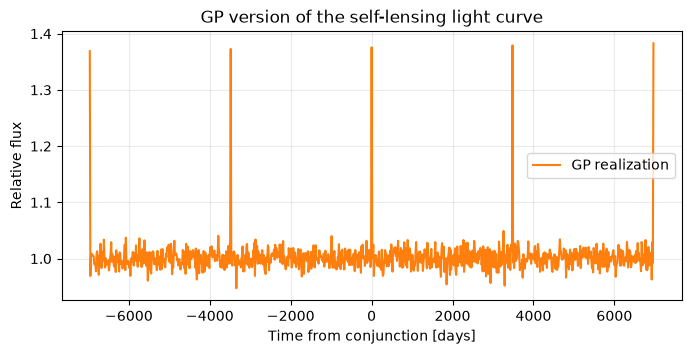

In [34]:
# Draw correlated variability around the identical self-lensing mean.
gp = GaussianProcess(
    2e-4 * kernels.Exp(scale=0.03),
    times,
    diag=(2e-3) ** 2,
    mean_value=deterministic_flux,
)
gp_flux = np.asarray(gp.sample(jax.random.key(42)))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times, gp_flux, color="C1", label="GP realization")
# ax.plot(times, deterministic_flux, color="C0", lw=1.5, label="Self-lensing mean")
ax.set(xlabel="Time from conjunction [days]", ylabel="Relative flux",
       title="GP version of the self-lensing light curve")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


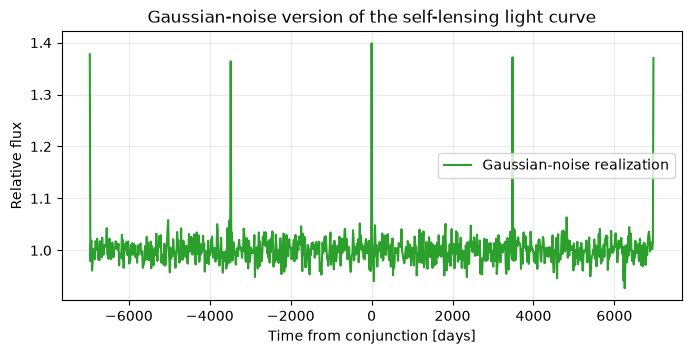

In [35]:
# Add independent Gaussian measurement noise to the same self-lensing signal.
rng = np.random.default_rng(42)
gaussian_noise_std = 2e-2
gaussian_flux = deterministic_flux + rng.normal(
    loc=0.0, scale=gaussian_noise_std, size=deterministic_flux.size
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times, gaussian_flux, color="C2", label="Gaussian-noise realization")
# ax.plot(times, deterministic_flux, color="C0", lw=1.5, label="Self-lensing mean")
ax.set(xlabel="Time from conjunction [days]", ylabel="Relative flux",
       title="Gaussian-noise version of the self-lensing light curve")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


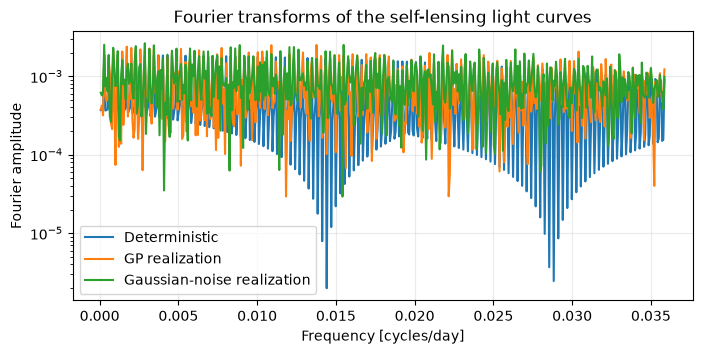

In [36]:
# Compare the Fourier amplitudes after removing each curve's constant baseline.
cadence_days = times[1] - times[0]
frequencies = np.fft.rfftfreq(times.size, d=cadence_days)
light_curves = {
    "Deterministic": deterministic_flux,
    "GP realization": gp_flux,
    "Gaussian-noise realization": gaussian_flux,
}
fourier_amplitudes = {
    label: np.abs(np.fft.rfft(flux - np.mean(flux))) / flux.size
    for label, flux in light_curves.items()
}

fig, ax = plt.subplots(figsize=(8, 3.5))
for label, amplitude in fourier_amplitudes.items():
    ax.plot(frequencies[1:], amplitude[1:], label=label)
ax.set(
    xlabel="Frequency [cycles/day]",
    ylabel="Fourier amplitude",
    title="Fourier transforms of the self-lensing light curves",
)
ax.set_yscale("log")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


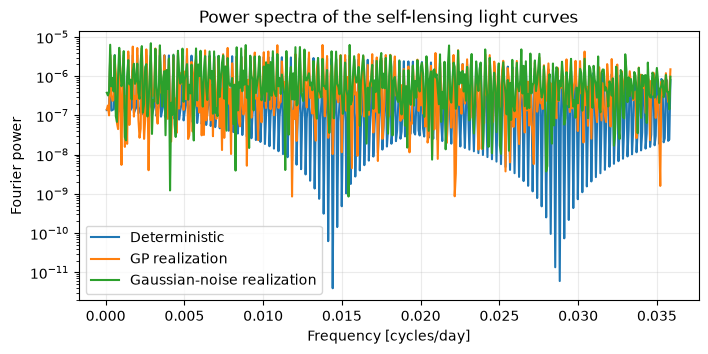

In [37]:
# The power spectrum is the squared Fourier amplitude.
power_spectra = {
    label: amplitude**2 for label, amplitude in fourier_amplitudes.items()
}

fig, ax = plt.subplots(figsize=(8, 3.5))
for label, power in power_spectra.items():
    ax.plot(frequencies[1:], power[1:], label=label)
ax.set(
    xlabel="Frequency [cycles/day]",
    ylabel="Fourier power",
    title="Power spectra of the self-lensing light curves",
)
ax.set_yscale("log")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


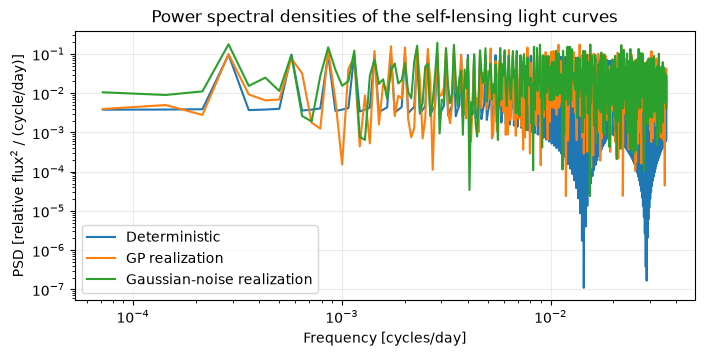

In [38]:
from scipy.signal import periodogram

# PSD: power normalized by the sampling frequency, in relative-flux^2 per cycle/day.
sampling_frequency = 1.0 / cadence_days
psds = {
    label: periodogram(flux, fs=sampling_frequency, detrend="constant")
    for label, flux in light_curves.items()
}

fig, ax = plt.subplots(figsize=(8, 3.5))
for label, (psd_frequencies, psd) in psds.items():
    ax.plot(psd_frequencies[1:], psd[1:], label=label)
ax.set(
    xlabel="Frequency [cycles/day]",
    ylabel="PSD [relative flux$^2$ / (cycle/day)]",
    title="Power spectral densities of the self-lensing light curves",
)
ax.set_yscale("log")
ax.set_xscale("log")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## A PSD-weighted FFT matched filter

The preceding plots describe the signal and noise; they do not yet detect the signal. A matched filter uses the deterministic self-lensing curve as a template and computes its correlation with an observed curve at every time shift. In Fourier space, each frequency is weighted by the inverse noise PSD, so frequencies with large noise contribute less to the detection statistic.

Here the GP realization acts as the observed light curve. In a real search, replace `observed_flux` with a normalized, detrended measured light curve sampled at the same cadence as the template.

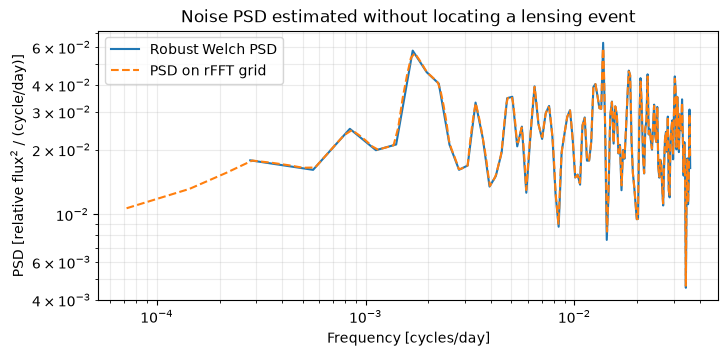

In [39]:
from scipy import signal

observed_flux = gp_flux

# Estimate the noise PSD before identifying a candidate event. Welch splits the
# complete light curve into overlapping sections; median averaging makes a short
# lensing pulse much less influential than a single full-series periodogram.
welch_segment_length = min(256, observed_flux.size)
welch_frequencies, estimated_noise_psd = signal.welch(
    observed_flux - np.median(observed_flux),
    fs=sampling_frequency,
    window="hann",
    nperseg=welch_segment_length,
    noverlap=welch_segment_length // 2,
    detrend="constant",
    average="median",
)

# Interpolate the PSD onto the rFFT grid and impose a small floor to avoid
# letting an accidentally tiny PSD bin dominate the filter.
noise_psd = np.interp(
    frequencies, welch_frequencies, estimated_noise_psd,
    left=estimated_noise_psd[0], right=estimated_noise_psd[-1],
)
noise_psd = np.maximum(noise_psd, 1e-3 * np.median(noise_psd))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.loglog(welch_frequencies[1:], estimated_noise_psd[1:], label="Robust Welch PSD")
ax.loglog(frequencies[1:], noise_psd[1:], "--", label="PSD on rFFT grid")
ax.set(
    xlabel="Frequency [cycles/day]",
    ylabel="PSD [relative flux$^2$ / (cycle/day)]",
    title="Noise PSD estimated without locating a lensing event",
)
ax.grid(alpha=0.25, which="both")
ax.legend()
plt.show()


### Whiten, correlate, and search over time shift

Both curves are mean-subtracted and tapered before transforming, which suppresses the artificial discontinuity at the endpoints. The weighted cross-spectrum is `conj(template_fft) * data_fft / noise_psd`. Its inverse FFT is the matched-filter score for every circular time lag. The normalization below makes the score dimensionless for comparison; for a calibrated detection significance, measure its noise-only distribution using representative background light curves.

This example contains repeated orbital pulses, so equivalent solutions separated by roughly one orbital period are expected. A search for isolated events would use a shorter single-pulse template and inspect a non-circular, padded correlation.

Strongest PSD-weighted correlation: lag = 0.00 days


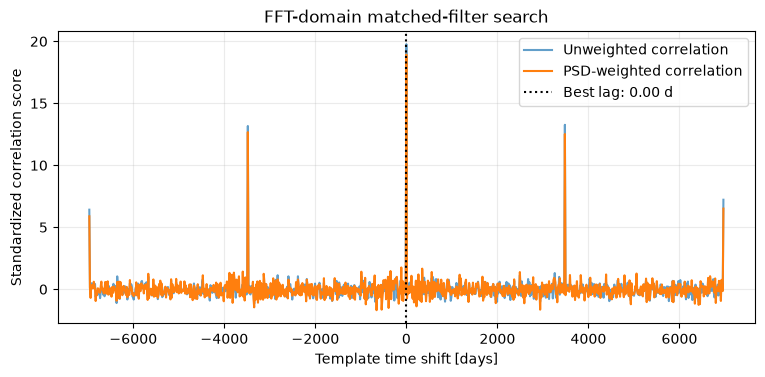

In [40]:
template_flux = deterministic_flux - np.mean(deterministic_flux)
data_flux = observed_flux - np.mean(observed_flux)
taper = signal.windows.tukey(times.size, alpha=0.1)

template_fft = np.fft.rfft(template_flux * taper)
data_fft = np.fft.rfft(data_flux * taper)

weighted_cross_spectrum = np.conj(template_fft) * data_fft / noise_psd
unweighted_cross_spectrum = np.conj(template_fft) * data_fft
weighted_score = np.fft.irfft(weighted_cross_spectrum, n=times.size)
unweighted_score = np.fft.irfft(unweighted_cross_spectrum, n=times.size)

# Standardizing lets the weighting change be compared visually without claiming
# a false analytic signal-to-noise ratio.
weighted_score = (weighted_score - weighted_score.mean()) / weighted_score.std()
unweighted_score = (unweighted_score - unweighted_score.mean()) / unweighted_score.std()

lag_days = np.arange(times.size) * cadence_days
lag_days[lag_days > times.size // 2 * cadence_days] -= times.size * cadence_days
best_lag_days = lag_days[np.argmax(weighted_score)]
print(f"Strongest PSD-weighted correlation: lag = {best_lag_days:.2f} days")

order = np.argsort(lag_days)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(lag_days[order], unweighted_score[order], alpha=0.7, label="Unweighted correlation")
ax.plot(lag_days[order], weighted_score[order], lw=1.5, label="PSD-weighted correlation")
ax.axvline(best_lag_days, color="k", ls=":", label=f"Best lag: {best_lag_days:.2f} d")
ax.set(
    xlabel="Template time shift [days]",
    ylabel="Standardized correlation score",
    title="FFT-domain matched-filter search",
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()


### What changes in a real search?

Estimate PSDs from many comparable non-event light curves when possible, or iteratively mask only high-confidence candidates and re-estimate the PSD. Generate a bank of templates spanning system parameters and score every template against each detrended observation. Finally, calibrate a detection threshold from noise-only data rather than treating the standardized score above as a formal SNR.